<a href="https://colab.research.google.com/github/cmauriciocrescente-upc/Dataset-en-Colab/blob/main/Outliers_HousePrices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Módulo 5 – Outliers: Dataset House Prices (Kaggle)

**Objetivo:** detectar outliers en `SalePrice` con un método visual (boxplot) y dos estadísticos (Z-Score e IQR), comparar resultados y decidir qué tratamiento corresponde.

> Recordatorio de la *Regla de Oro*: nunca eliminar un outlier sin documentar por qué.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')

## Paso 0 – Carga del dataset

In [ ]:
df = pd.read_csv('house_prices.csv')
precio = df['SalePrice']
print(df.shape)
precio.describe().round(0)

(1460, 81)


count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

## Paso 1 – Detección visual con boxplot y distribución

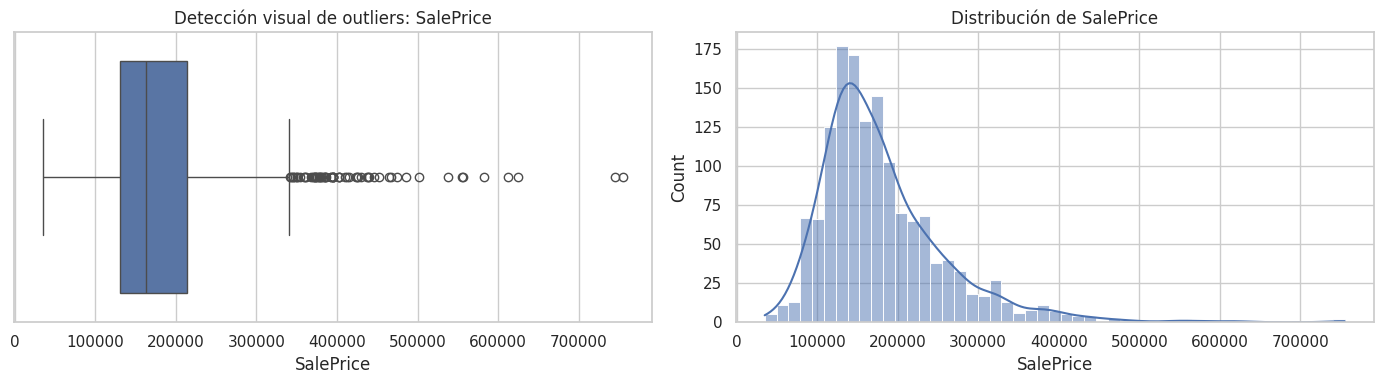

Asimetría (skew): 1.88


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=precio, ax=ax[0])
ax[0].set_title('Detección visual de outliers: SalePrice')
sns.histplot(precio, kde=True, ax=ax[1])
ax[1].set_title('Distribución de SalePrice')
plt.tight_layout(); plt.show()
print(f'Asimetría (skew): {precio.skew():.2f}')

**Lectura:** el boxplot muestra una cola larga de puntos a la derecha y el histograma confirma una distribución **sesgada a la derecha** (skew > 1). Esto es relevante: el Z-Score asume normalidad, así que se espera que se comporte peor que el IQR.

## Paso 2 – Z-Score

In [ ]:
z_scores = stats.zscore(precio)
abs_z_scores = np.abs(z_scores)
outliers_z = df[abs_z_scores > 3]
print(f"Outliers detectados por Z-Score (>3): {len(outliers_z)}")
outliers_z[['Id','SalePrice','GrLivArea','OverallQual']].sort_values('SalePrice', ascending=False).head(10)

Outliers detectados por Z-Score (>3): 22


,Id,SalePrice,GrLivArea,OverallQual
691,692,755000,4316,10
1182,1183,745000,4476,10
1169,1170,625000,3627,10
898,899,611657,2364,9
803,804,582933,2822,9
1046,1047,556581,2868,9
440,441,555000,2402,10
769,770,538000,3279,8
178,179,501837,2234,9
798,799,485000,3140,9


## Paso 3 – IQR y filtrado

In [ ]:
Q1 = precio.quantile(0.25)
Q3 = precio.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Q1={Q1:,.0f}  Q3={Q3:,.0f}  IQR={IQR:,.0f}")
print(f"Límites IQR: [{lower_bound:,.0f}, {upper_bound:,.0f}]")

# Filtramos el dataset
df_iqr_filtered = df[(precio >= lower_bound) & (precio <= upper_bound)]
print(f"Outliers eliminados por IQR: {len(df) - len(df_iqr_filtered)}")
print(f"Outliers por debajo: {(precio < lower_bound).sum()} | por encima: {(precio > upper_bound).sum()}")

Q1=129,975  Q3=214,000  IQR=84,025
Límites IQR: [3,938, 340,038]
Outliers eliminados por IQR: 61
Outliers por debajo: 0 | por encima: 61


## Paso 4 – Comparación de métodos

In [ ]:
idx_z = set(df.index[abs_z_scores > 3])
idx_iqr = set(df.index[(precio < lower_bound) | (precio > upper_bound)])
print(f"Solo Z-Score: {len(idx_z - idx_iqr)} | Solo IQR: {len(idx_iqr - idx_z)} | Ambos: {len(idx_z & idx_iqr)}")

resumen = pd.DataFrame({
    'Original': precio.describe(),
    'Sin outliers IQR': df_iqr_filtered['SalePrice'].describe()}).round(0)
resumen

Solo Z-Score: 0 | Solo IQR: 39 | Ambos: 22


,Original,Sin outliers IQR
count,1460.0,1399.0
mean,180921.0,170237.0
std,79443.0,59230.0
min,34900.0,34900.0
25%,129975.0,129000.0
50%,163000.0,159500.0
75%,214000.0,203500.0
max,755000.0,340000.0


**Conclusión:** el IQR marca más observaciones que el Z-Score porque la media y la desviación estándar están *infladas por los propios outliers* (el Z-Score no es robusto). Por eso para `SalePrice` se opta por **IQR**.

Además, las casas caras no son necesariamente errores: pueden ser propiedades legítimas de lujo. Se analiza esto en el siguiente paso.

## Paso 5 – ¿Error o dato extremo válido? (análisis bivariante)

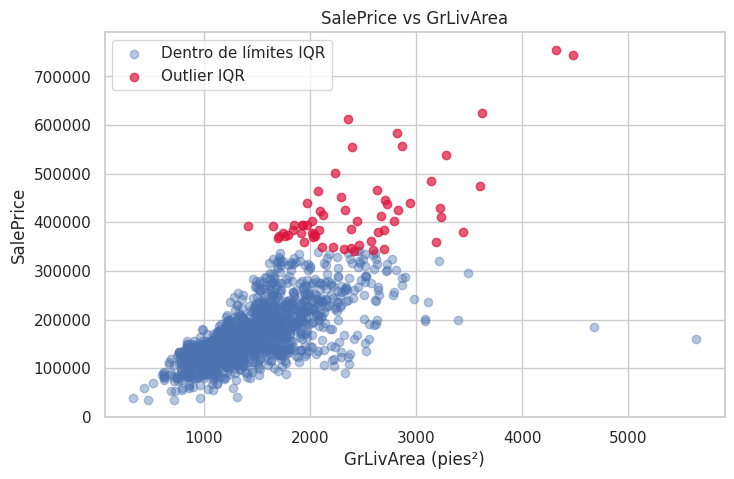

,Id,GrLivArea,SalePrice,OverallQual,SaleCondition
523,524,4676,184750,10,Partial
1298,1299,5642,160000,10,Partial


In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ok = ~df.index.isin(idx_iqr)
ax.scatter(df.loc[ok,'GrLivArea'], df.loc[ok,'SalePrice'], alpha=.4, label='Dentro de límites IQR')
ax.scatter(df.loc[~ok,'GrLivArea'], df.loc[~ok,'SalePrice'], color='crimson', alpha=.7, label='Outlier IQR')
ax.set_xlabel('GrLivArea (pies²)'); ax.set_ylabel('SalePrice'); ax.legend()
ax.set_title('SalePrice vs GrLivArea')
plt.show()

# Casas muy grandes y baratas: combinación inusual (outlier multivariante)
sospechosas = df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)]
sospechosas[['Id','GrLivArea','SalePrice','OverallQual','SaleCondition']]

**Lectura:** la mayoría de los puntos rojos siguen la tendencia (más superficie → más precio): son **valores extremos válidos**. En cambio, las casas de más de 4000 pies² vendidas a precios bajos rompen la relación; no son extremas en una sola variable pero sí como combinación (outliers multivariantes, ver Bloque 3). Esas pocas observaciones son candidatas a revisión, y son las que la documentación original del dataset de Ames sugiere remover.

## Paso 6 – Tratamiento alternativo: transformación logarítmica

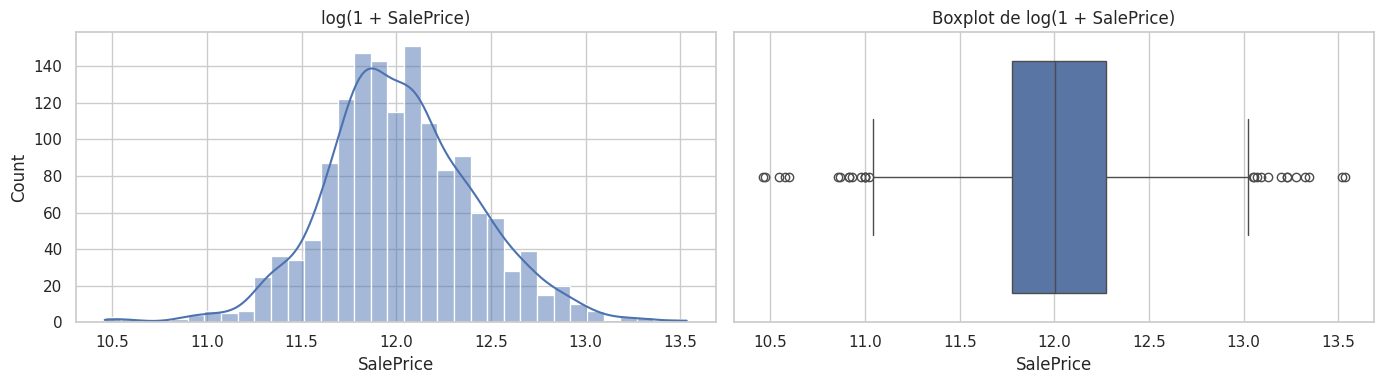

Skew original: 1.88 -> Skew log: 0.12
Outliers IQR en SalePrice: 61 -> en log(SalePrice): 28


In [ ]:
log_precio = np.log1p(precio)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(log_precio, kde=True, ax=ax[0]); ax[0].set_title('log(1 + SalePrice)')
sns.boxplot(x=log_precio, ax=ax[1]); ax[1].set_title('Boxplot de log(1 + SalePrice)')
plt.tight_layout(); plt.show()

q1, q3 = log_precio.quantile([.25,.75]); i = q3-q1
n_log = ((log_precio < q1-1.5*i) | (log_precio > q3+1.5*i)).sum()
print(f"Skew original: {precio.skew():.2f} -> Skew log: {log_precio.skew():.2f}")
print(f"Outliers IQR en SalePrice: {len(idx_iqr)} -> en log(SalePrice): {n_log}")

## Conclusiones – House Prices

- **Métodos:** Boxplot (visual), Z-Score e IQR (estadísticos).
- **Elección:** IQR, por el sesgo a la derecha de `SalePrice` (el Z-Score depende de media y desvío, sensibles a los outliers).
- **Tratamiento:** el filtrado por IQR se hizo como ejercicio; en un modelo real **no se eliminarían** las casas caras legítimas, sino que se aplicaría **transformación logarítmica**, que reduce fuertemente la asimetría y los outliers marcados.
- **Revisión puntual:** las casas muy grandes y baratas (outliers multivariantes) merecen revisión individual y documentación antes de cualquier eliminación.